Statevector([0.-0.35355339j, 0.+0.35355339j, 0.-0.35355339j,
             0.-0.35355339j, 0.+0.35355339j, 0.-0.35355339j,
             0.+0.35355339j, 0.+0.35355339j],
            dims=(2, 2, 2))


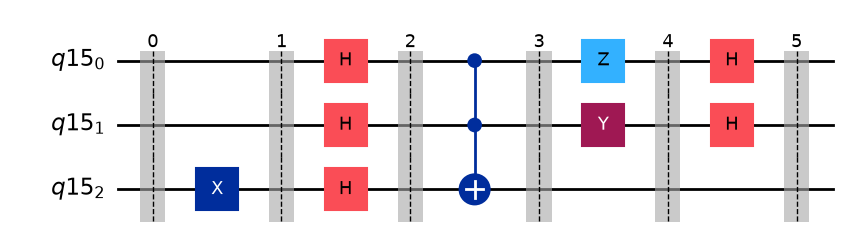

In [ ]:
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector
import math

qr = QuantumRegister(3)
qc = QuantumCircuit(qr)
qc.barrier(label='0')
qc.x(2)
qc.barrier(label='1')
qc.h(0)
qc.h(1)
qc.h(2)
qc.barrier(label='2')
qc.ccx(0, 1, 2)
qc.barrier(label='3')
qc.z(0)
qc.y(1)
qc.barrier(label='4')
qc.h(0)
qc.h(1)
qc.barrier(label='5')



sv = Statevector(qc)
qc.draw('mpl')

In [75]:
sv.draw('latex')

<IPython.core.display.Latex object>

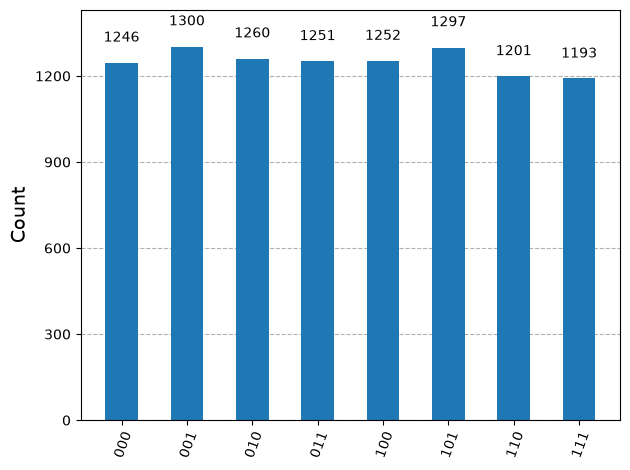

In [12]:
sampler = StatevectorSampler()
result = sampler.run([qc], shots=10000).result()
plot_histogram(result[0].data.meas.get_counts())

## Análise algébrica

In [21]:
%%latex
\begin{align}
    H = \frac{1}{\sqrt{2}} (\ket{0}\bra{0}+\ket{0}\bra{1}+\ket{1}\bra{0}-\ket{1}\bra{1}) \\
    H\ket{0} = \frac{1}{\sqrt{2}} (\ket{0}+\ket{1}) = \ket{+} \\
    H\ket{1} = \frac{1}{\sqrt{2}} (\ket{0}-\ket{1}) = \ket{-} \\

    X = \ket{1}\bra{0}+\ket{0}\bra{1}\\
    Y = i(\ket{1}\bra{0} - \ket{0}\bra{1}) \\
    Z = \ket{0}\bra{0}-\ket{1}\bra{1} \\
    CCX = \ket{000}\bra{000}+\ket{001}\bra{001}+\ket{010}\bra{010}+\ket{011}\bra{011}+\ket{100}\bra{100}+\ket{101}\bra{101}+\ket{111}\bra{110}+\ket{110}\bra{111}
\end{align}

<IPython.core.display.Latex object>

In [61]:
%%latex
\begin{align}
\ket{\psi_0} = \ket{0} \otimes \ket{0} \otimes \ket{0} \\
\ket{\psi_1} = \ket{0} \otimes \ket{0} \otimes \ket{1} \\
\ket{\psi_2} = H\ket{0} \otimes H\ket{0} \otimes H\ket{1} =  \ket{+} \otimes \ket{+} \otimes \ket{-}\\
\ket{\psi_2} = \frac{1}{\sqrt{2}} (\ket{0}+\ket{1}) \otimes \frac{1}{\sqrt{2}} (\ket{0}+\ket{1}) \otimes \frac{1}{\sqrt{2}} (\ket{0}-\ket{1})\\
\ket{\psi_2} = \frac{1}{2\sqrt{2}} (\ket{000}-\ket{001}+\ket{010}-\ket{011}+\ket{100}-\ket{101}+\ket{110}-\ket{111}) \\
\ket{\psi_3} = CCX\ket{\psi_2} = \frac{1}{2\sqrt{2}} (\ket{000}-\ket{001}+\ket{010}-\ket{011}+\ket{100}-\ket{101}+\ket{111}-\ket{110}) \\
\ket{\psi_4} = Z_0Y_1\ket{\psi_3} = Z_0\frac{i}{2\sqrt{2}} (\ket{010}-\ket{011}-\ket{000}+\ket{001}+\ket{110}-\ket{111}-\ket{101}+\ket{100}) \\
\ket{\psi_4} = \frac{i}{2\sqrt{2}} (\ket{010}-\ket{011}-\ket{000}+\ket{001}-\ket{110}+\ket{111}+\ket{101}-\ket{100}) \\
\ket{\psi_5} = H_0H_1 \ket{\psi_4} = H_0\frac{i}{2\sqrt{2}} \frac{1}{\sqrt{2}} [(\ket{000}-\ket{010})-(\ket{001}-\ket{011})-(\ket{000}+\ket{010})\\
+(\ket{001}+\ket{011})-(\ket{100}-\ket{110})+(\ket{101}-\ket{111})+(\ket{101}+\ket{111})-(\ket{100}+\ket{110})] \\
= H_0 \frac{i}{4} (-2\ket{010} + 2\ket{011} - 2\ket{100} + 2\ket{101}) = H_0 \frac{i}{2} (-\ket{010} + \ket{011} - \ket{100} + \ket{101}) \\
= \frac{i}{2\sqrt{2}} ( -(\ket{010} + \ket{110}) + (\ket{011} + \ket{111}) -(\ket{000} - \ket{100}) + (\ket{001} - \ket{101}) ) \\
\ket{\psi_5} = \frac{i}{2\sqrt{2}} (-\ket{000} + \ket{001} - \ket{010} + \ket{011} + \ket{100} - \ket{101} - \ket{110} + \ket{111} ) \\
\end{align}

<IPython.core.display.Latex object>

Fiz o meus calculos como Big Endian, o bit mais significativo é o primeiro registrador. Já na álgebra do circuito é Little Endian. Comparando com a álgebra do circuito convertendo, os valores batem.

In [88]:
sv5.draw('latex')

<IPython.core.display.Latex object>

In [98]:
from IPython.display import display, Math, Latex
qc = QuantumCircuit(qr)
sv0 = Statevector(qc)
qc.barrier(label='0')
qc.x(2)
sv1 = Statevector(qc)
qc.barrier(label='1')
qc.h(0)
qc.h(1)
qc.h(2)
sv2 = Statevector(qc)
qc.barrier(label='2')

qc.ccx(0, 1, 2)
sv3 = Statevector(qc)
qc.barrier(label='3')

qc.z(0)
qc.y(1)
sv4 = Statevector(qc)
qc.barrier(label='4')
qc.h(0)
qc.h(1)
sv5 = Statevector(qc)
qc.barrier(label='5')
display(Math('\\ket{\\psi_0} ='))
display(sv0.draw('latex'))

display(Math('\\ket{\\psi_1} ='))
display(sv1.draw('latex'))

display(Math('\\ket{\\psi_2} ='))
display(sv2.draw('latex'))

display(Math('\\ket{\\psi_3} ='))
display(sv3.draw('latex'))

display(Math('\\ket{\\psi_4} ='))
display(sv4.draw('latex'))

display(Math('\\ket{\\psi_5} ='))
display(sv5.draw('latex'))

<IPython.core.display.Math object>

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

<IPython.core.display.Latex object>

... (2 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

<IPython.core.display.Latex object>